# Reading SCRIP remapping grids with `pyramids-mesh`

**SCRIP** (Spherical Coordinate Remapping and Interpolation Package) defines the NetCDF grid-description convention used across climate modelling to specify *how to remap* fields between grids. A SCRIP file does not store a solver mesh so much as a **list of cells by their corners**: `grid_corner_lat`/`grid_corner_lon` give each cell's vertices (here `(384, 4)` — 384 quadrilateral cells, 4 corners each), `grid_center_lat`/`lon` the centres, and `grid_imask` an active-cell mask.

This notebook reads the `outCSne8` cubed-sphere SCRIP grid (an ne8 cube, 384 cells) into a pyramids `UgridDataset` and tours the operations it supports. Unlike MPAS/ICON, SCRIP corner coordinates are in **degrees**.

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 3. Locate the example file

This notebook lives in `docs/examples/`, so `examples/data/` is two levels up. The SCRIP sample is `scrip/outCSne8.nc`, a cubed-sphere ne8 remapping grid from the UXarray test suite.

Paths inside a notebook are always written **relative to the notebook itself**, and pyramids' `read_file` accepts a `pathlib.Path` directly — we pass the `Path`, never `str(path)`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "scrip" / "outCSne8.nc"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/scrip/outCSne8.nc'), True)

## 4. Read the mesh

`UgridDataset.read_file(path, driver="scrip")` dispatches the file to the `scrip` driver, which parses it and hands back a `UgridDataset` — the same pyramids type produced from a native UGRID NetCDF file. We name the driver explicitly here because several formats share the `.nc` suffix; `read_file` can auto-detect, but being explicit is unambiguous.

In [3]:
ds = UgridDataset.read_file(mesh_file, driver="scrip")
type(ds).__name__

'UgridDataset'

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

From here nothing in the API remembers the data came from a SCRIP grid — it is a first-class pyramids object.

## 5. Explore the dataset

A `UgridDataset` exposes summary properties describing the whole mesh: `n_node` / `n_face` (size), `crs` / `epsg` (georeferencing, if the format recorded any), `bounds` (spatial extent), and `data_variable_names` (any attached fields).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": ds.bounds,
    "data_variable_names": ds.data_variable_names,
})

n_node                                       407
n_face                                       384
crs                                         None
epsg                                        None
bounds                 (0.0, -90.0, 360.0, 90.0)
data_variable_names                           []
dtype: object

**384 quadrilateral faces** assembled from **407 unique nodes** (shared corners are de-duplicated on read). `crs`/`epsg` are `None` — SCRIP records lon/lat with no CRS object — and `data_variable_names` is empty: a SCRIP grid is a geometry description, not a field dataset. The `bounds` of `(0, -90, 360, 90)` already hint these coordinates are in degrees.

## 6. Coordinates are in DEGREES

SCRIP corner/centre coordinates are stored in **degrees** of longitude/latitude — unlike the radian MPAS and ICON grids. The range makes it obvious: longitude `0 → 360`, latitude `−90 → 90`.

In [6]:
nx, ny = np.asarray(ds.mesh.node_x), np.asarray(ds.mesh.node_y)
pd.Series({
    "node_x min/max": (float(nx.min()), float(nx.max())),
    "node_y min/max": (float(ny.min()), float(ny.max())),
    "two_pi": float(2*np.pi), "half_pi": float(np.pi/2),
})

node_x min/max     (0.0, 360.0)
node_y min/max    (-90.0, 90.0)
two_pi                 6.283185
half_pi                1.570796
dtype: object

`node_x` spans the full **`0 → 360`** and `node_y` the full **`−90 → 90`** — these are degrees, so (once a geographic CRS is assigned) they are already in the units most GIS tools expect, no radian conversion needed.

## 7. The underlying `Mesh2d` topology

`ds.mesh` is the `Mesh2d` holding the raw topology. The arrays you reach for most often are `node_x`/`node_y` (node coordinates), `face_node_connectivity.data` — the `(n_face, k)` table listing the node indices of each face — and `face_areas` (one value per face).

In [7]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
{
    "n_node": int(mesh.node_x.shape[0]),
    "connectivity_shape": conn.shape,
    "face_areas_shape": np.asarray(mesh.face_areas).shape,
    "face_centroids_shape": np.asarray(mesh.face_centroids).shape,
}

{'n_node': 407,
 'connectivity_shape': (384, 4),
 'face_areas_shape': (384,),
 'face_centroids_shape': (2, 384)}

The connectivity shape is **`(384, 4)`**: **four** nodes per face — SCRIP cubed-sphere cells are quadrilaterals. That `k = 4` (versus `3` for a triangular grid) is why circumcenters will not apply.

## 8. The wireframe

The simplest visualization needs no data — just draw the cell edges. `plot_outline()` renders the mesh skeleton through cleopatra; it is the fastest sanity check that a file read in correctly.

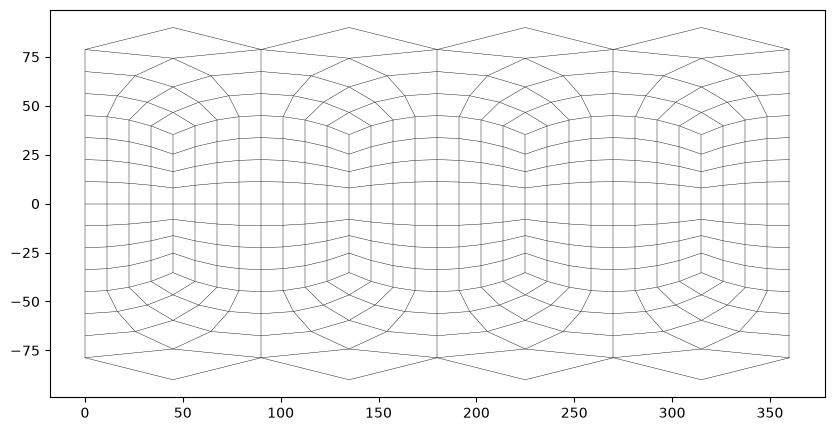

In [8]:
ds.plot_outline()


The wireframe shows the cubed-sphere layout unrolled onto the lon/lat plane: six square panels whose quadrilateral cells distort toward the poles, where constant-degree spacing stretches them.

## 9. A data map: per-cell area

A SCRIP grid carries no field values, so we synthesise one. We compute each cell's area from the geometry and attach it as a face-located variable with `with_variable(...)`, which returns a **new** dataset (the original `ds` is left untouched). Colouring by it produces the generic pyramids data-map that any per-cell field (depth, velocity, …) would use.

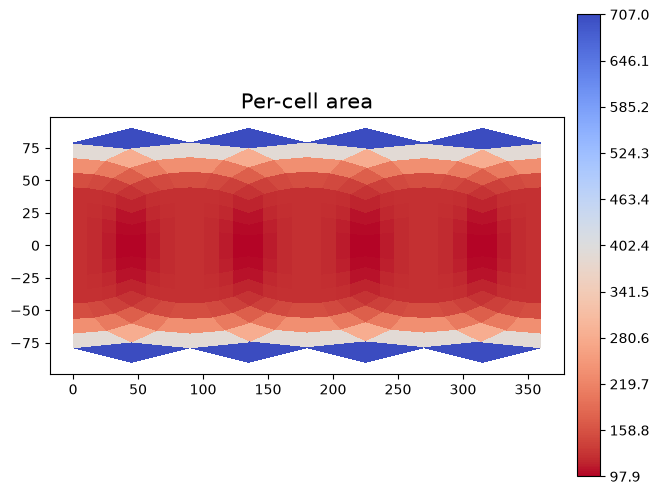

In [9]:
d2 = ds.with_variable("face_area", np.asarray(mesh.face_areas), location="face")
d2.plot("face_area", cmap="viridis", colorbar=True, title="Per-cell area")


Each quad is shaded by area (in degree-squared units). The map brightens toward the equator and dims toward the poles — the familiar lon/lat distortion where equal angular steps enclose less area at high latitude.

`summary()` reports per-variable statistics (count, min, max, mean, std) for every attached field.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
face_area,384,97.860238,707.01908,158.203125,101.776481


The single `face_area` row quantifies that equator-to-pole size variation (a wide min–max spread), the numeric companion to the colour map.

## 10. GIS operations, for free

Because the mesh is a pyramids object, the pyramids GIS layer applies directly — none of these methods live in `pyramids-mesh`. We tour a few.

### Faces as a `GeoDataFrame`

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or for spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((315 -35.264, 326.25 -39.742, 326.25 ..."
1,"POLYGON ((326.25 -39.742, 337.5 -42.734, 337.5..."
2,"POLYGON ((337.5 -42.734, 348.75 -44.444, 348.7..."
3,"POLYGON ((348.75 -44.444, 360 -45, 360 -33.75,..."
4,"POLYGON ((0 -45, 11.25 -44.444, 11.25 -33.238,..."


One row per face, each carrying its cell polygon. Plotting the `GeoDataFrame` directly with geopandas draws every face as a filled polygon — a second, vector-native view of the same mesh.

<Axes: xlabel='x', ylabel='y'>

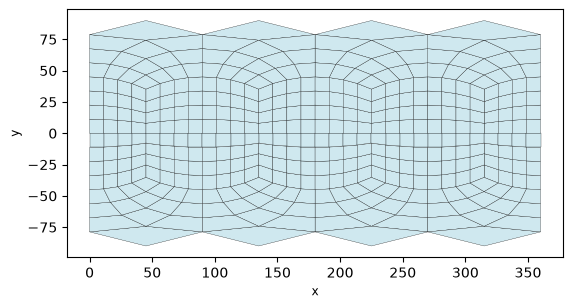

In [12]:
gdf.plot(edgecolor="black", linewidth=0.2, facecolor="#cfe8ef")


Each row is a quadrilateral cell polygon. The CRS is unset (inherited `None`); assign a geographic CRS before export.

### Bounding polygon

`bounding_polygon()` dissolves the cells into the grid's outer boundary. For this cubed-sphere grid, unrolled across the full `0–360` longitude range, it returns a shapely `Polygon`.

In [13]:
poly = ds.bounding_polygon()
{"type": type(poly).__name__, "bounds": ds.bounds}

{'type': 'Polygon', 'bounds': (0.0, -90.0, 360.0, 90.0)}

A single `Polygon` covering the full global extent — an ordinary shapely geometry ready for intersection, buffering or export.

### Circumcenters — not applicable

`circumcenters()` is **defined only for triangular meshes**. SCRIP is a **quadrilateral** mesh, so calling it raises `ValueError: circumcenters is only defined for triangular meshes.` We show the guard rather than force it — a circumcenter has no unique definition for a polygon with more than three sides.

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped:", e)

skipped: circumcenters is only defined for triangular meshes.


Expected: the operation is simply undefined for this cell shape. A triangular dual mesh would be the prerequisite for finite-volume circumcenter schemes on this grid.

### Boundary edges and face adjacency

`exterior_edges()` returns the indices of the edges that lie on the mesh boundary (each interior edge is shared by two faces; a boundary edge by one). `sparse_adjacency()` returns the face–face adjacency as a SciPy sparse matrix — the graph a flow solver walks.

In [15]:
ee = np.asarray(ds.exterior_edges())
adj = ds.sparse_adjacency()
{
    "n_boundary_edges": int(ee.shape[0]),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}

{'n_boundary_edges': 44, 'adjacency_shape': (384, 384), 'adjacency_nnz': 1492}

The adjacency matrix is `(384, 384)` with two non-zeros per shared edge; the boundary-edge count reflects the rim of the unrolled cubed sphere (cells that would meet across a cube edge are not stitched in the flat lon/lat layout).

### Connected components

`connected_components()` labels each face by which connected piece of the adjacency graph it belongs to. The number of distinct labels tells you whether the mesh is one contiguous surface or several disjoint pieces.

In [16]:
labels = np.asarray(ds.connected_components())
n_comp = int(np.unique(labels).size)
{"n_components": n_comp, "counts": np.bincount(labels).tolist()}

{'n_components': 1, 'counts': [384]}

**One** component: every cell connects to its neighbours, so the SCRIP grid reads back as a single contiguous surface.

### Cropping to a bounding box

`crop(bbox=(xmin, ymin, xmax, ymax))` returns a new `UgridDataset` holding only the faces inside the box — the mesh equivalent of a spatial window. (`subset_by_bounds(xmin, ymin, xmax, ymax)` does the same with positional arguments.) We crop to one quadrant of the extent and plot the result.

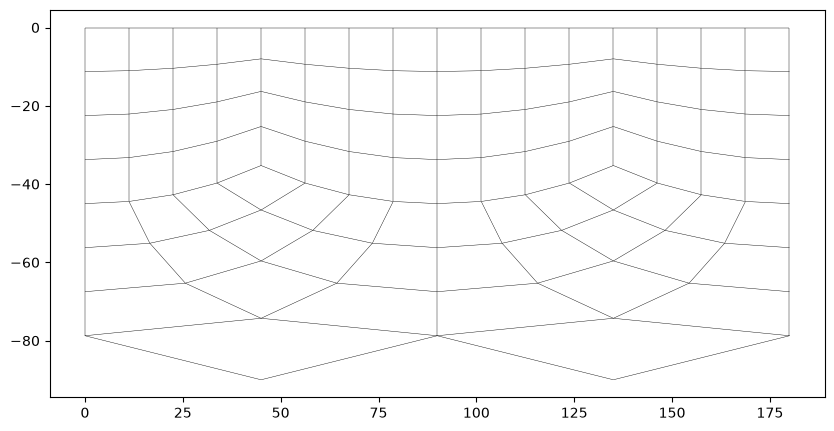

In [17]:
b = ds.bounds
bbox = (b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2)
cropped = ds.crop(bbox=bbox)
cropped.plot_outline()


Cropping to one quadrant of the `0–360 / −90–90` extent keeps roughly the cells of one lon/lat window — here a block of the cubed-sphere cells.

### Writing the mesh back out

`to_file(path, driver=...)` serialises the mesh through any **write-capable** driver. We round-trip to Stanford **PLY** (`driver="ply"`), which stores arbitrary polygon faces, into a temp file and read it back to confirm the topology survived.

In [18]:
import tempfile
out = Path(tempfile.gettempdir()) / "scrip_roundtrip.ply"
ds.to_file(out, driver="ply")
back = UgridDataset.read_file(out, driver="ply")
{"wrote_bytes": out.stat().st_size, "n_face_back": back.n_face, "matches": back.n_face == ds.n_face}

{'wrote_bytes': 19800, 'n_face_back': 384, 'matches': True}

The face count survives the round-trip: the mesh we read from a SCRIP grid wrote cleanly to a different format and came back identical. PLY is used because this format's own driver is read-only — `to_file` dispatches to whichever driver advertises a write capability.

### Back to `xarray`

`to_xarray()` exposes the dataset as an `xarray.Dataset` of UGRID variables — the bridge to the wider scientific-Python stack (dask, NetCDF export, CF tooling).

In [19]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.dims)

('Dataset',
 ['mesh2d_scalar', 'mesh2d_nNodes', 'mesh2d_nFaces', 'mesh2d_nMaxFaceNodes'])

A standard `xarray.Dataset`: from here the mesh can be written to NetCDF, chunked with dask, or fed to any CF-aware tool.

## 11. What we *cannot* do here, and why

Two pyramids operations are unavailable on this mesh, and the reasons are instructive:

- **`to_crs(epsg)` — skipped.** This grid carries **no CRS** (`crs` is `None` above), so pyramids refuses to reproject: `to_crs` raises *"Cannot reproject: source CRS is unknown."* You would first assign the known CRS (these global grids are geographic lon/lat on a sphere) and only then reproject.
- **`rasterize_like(...)` / `regrid(...)` — out of scope here.** Burning the mesh onto a raster grid or remapping between meshes is a genuine pyramids capability, but it needs a target raster/mesh and a resampling choice to be meaningful — a topic for a dedicated regridding tutorial, not this format tour.

## Takeaway

- The `scrip` driver reads a SCRIP remapping grid (corner-list convention) into a pyramids `UgridDataset`, de-duplicating shared corners into `n_node` nodes.
- SCRIP cubed-sphere cells are **quadrilaterals** (`k = 4`) with coordinates in **degrees** (`0–360 / −90–90`), so `circumcenters` is skipped (triangles only).
- The grid is geometry-only (no CRS, no fields); we attached a geometric `face_area` to map it.
- GIS operations — `to_geodataframe`, `bounding_polygon`, adjacency/components, crop, PLY round-trip, `to_xarray` — all apply, while `to_crs` is skipped because no CRS is recorded.